Text(0.5, 1.0, 'Malin Head Windspeed: 2024-11-24')

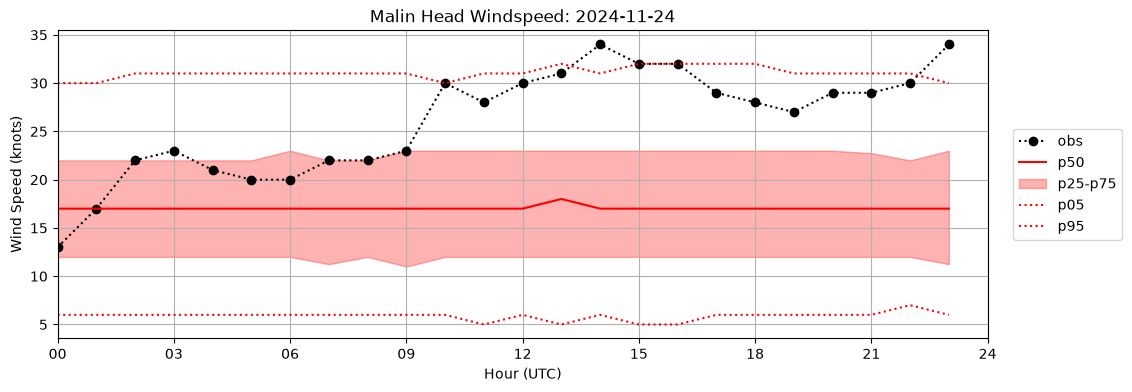

In [24]:
import numpy as np
import pandas as pd
    
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

MH_OBS = pd.read_csv("./data/week2/hly1575.csv",
                      skiprows=41, 
                      usecols=[0, 12],
                      index_col='date',
                      parse_dates=['date'],
                      date_format='%d-%b-%Y %H:%M',
                      low_memory=False)
MH_OBS['wdsp'] = pd.to_numeric(MH_OBS['wdsp'], errors='coerce')
MH_DAY = MH_OBS.loc['2024-11-24']
doy = MH_DAY.index.dayofyear[0]
#print(doy)
MH_CLIM = MH_OBS.loc['1991-01-01':'2020-12-31']
doy_CLIM = MH_CLIM.index.dayofyear
#print(doy_CLIM[0])
year_len = np.where(MH_CLIM.index.is_leap_year, 366, 365)
#print(year_len[0])
diff = np.abs(doy_CLIM - doy)
#print(diff[0])
circ_diff = np.minimum(diff, year_len - diff)
#print(circ_diff)
CLIM_window = MH_CLIM[circ_diff <= 15].copy()
#print(CLIM_window)
hlyclim_05 = CLIM_window.groupby(CLIM_window.index.hour).quantile(0.05)
hlyclim_25 = CLIM_window.groupby(CLIM_window.index.hour).quantile(0.25)
hlyclim_50 = CLIM_window.groupby(CLIM_window.index.hour).quantile(0.5)
hlyclim_75 = CLIM_window.groupby(CLIM_window.index.hour).quantile(0.75)
hlyclim_95 = CLIM_window.groupby(CLIM_window.index.hour).quantile(0.95)


fig, ax = plt.subplots(figsize=(12,4))

ax.plot(MH_DAY.index.hour, MH_DAY["wdsp"],
        color='black', marker='o', linestyle=':', label='obs')
ax.plot(hlyclim_50.index, hlyclim_50["wdsp"],
        color='red', linestyle='-', label='p50')
ax.fill_between(hlyclim_25.index, hlyclim_25["wdsp"], hlyclim_75["wdsp"], 
                alpha=0.3, color='red', label='p25-p75')
ax.plot(hlyclim_05.index, hlyclim_05["wdsp"],
        color='red', linestyle=':', label='p05')
ax.plot(hlyclim_95.index, hlyclim_95["wdsp"],
        color='red', linestyle=':', label='p95')

plt.ylabel('Wind Speed (knots)')
plt.title('Malin Head Wind Speed: ' + MH_DAY.index.strftime('%Y-%m-%d')[0])
plt.grid()

ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

ax.set_xticks(range(0, 25, 3))
ax.set_xticklabels([f"{h:02d}" for h in range(0, 25, 3)])
ax.set_xlim(0, 24)
ax.set_xlabel("Hour (UTC)")

plt.title('Malin Head Windspeed: '+MH_DAY.index.strftime('%Y-%m-%d')[0] )

# compare the peak 

Bert's peak (34.0 knots) exceeded 86.6% of past daily peaks


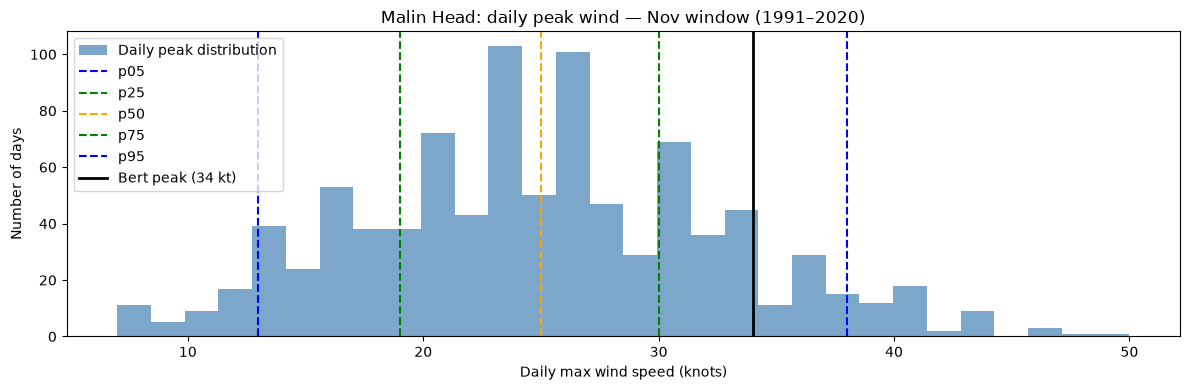

In [26]:
import numpy as np
import pandas as pd
    
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

MH_OBS = pd.read_csv("./data/week2/hly1575.csv",
                      skiprows=41, 
                      usecols=[0, 12],
                      index_col='date',
                      parse_dates=['date'],
                      date_format='%d-%b-%Y %H:%M',
                      low_memory=False)
MH_OBS['wdsp'] = pd.to_numeric(MH_OBS['wdsp'], errors='coerce')
MH_DAY = MH_OBS.loc['2024-11-24']
doy = MH_DAY.index.dayofyear[0]
#print(doy)
MH_CLIM = MH_OBS.loc['1991-01-01':'2020-12-31']
doy_CLIM = MH_CLIM.index.dayofyear
#print(doy_CLIM[0])
year_len = np.where(MH_CLIM.index.is_leap_year, 366, 365)
#print(year_len[0])
diff = np.abs(doy_CLIM - doy)
#print(diff[0])
circ_diff = np.minimum(diff, year_len - diff)
#print(circ_diff)
CLIM_window = MH_CLIM[circ_diff <= 15].copy()
#print(CLIM_window)
# Daily peak wind speeds from the climate window
daily_peaks = CLIM_window['wdsp'].groupby(CLIM_window.index.normalize()).max()

# Bert's peak
bert_peak = MH_DAY['wdsp'].max()

# Percentile rank
percentile = (daily_peaks < bert_peak).mean() * 100
print(f"Bert's peak ({bert_peak:.1f} knots) exceeded {percentile:.1f}% of past daily peaks")

# Quantiles of daily peaks
qs = daily_peaks.quantile([0.05, 0.25, 0.50, 0.75, 0.95])

# Plot
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(daily_peaks, bins=30, color='steelblue', alpha=0.7, label='Daily peak distribution')

colours = ['blue', 'green', 'orange', 'green', 'blue']
labels  = ['p05', 'p25', 'p50', 'p75', 'p95']
for q, c, lbl in zip(qs, colours, labels):
    ax.axvline(q, color=c, linestyle='--', label=lbl)

ax.axvline(bert_peak, color='black', linewidth=2, label=f'Bert peak ({bert_peak:.0f} kt)')
ax.set_xlabel('Daily max wind speed (knots)')
ax.set_ylabel('Number of days')
ax.set_title('Malin Head: daily peak wind — Nov window (1991–2020)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()